# EDA — Demanda de taxis amarillos en NYC (oct-2024 a mar-2025)

Análisis exploratorio sobre la **capa gold** (21,4 M viajes limpios). Cinco preguntas de negocio:

1. ¿Cómo evoluciona la demanda diaria?
2. ¿Cuándo se concentra (hora × día)?
3. ¿Dónde se concentra?
4. ¿Qué pasó con la demanda tras el cargo por congestión (5-ene-2025)?
5. ¿Qué implica la estructura de los datos para el modelo predictivo?

> Requisito: haber ejecutado `dbt build` (ver README). La ruta de la base se puede cambiar con la variable `NYC_DUCKDB_PATH`.

In [1]:
import os
import duckdb
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

DB = os.environ.get("NYC_DUCKDB_PATH", "../data/warehouse.duckdb")
con = duckdb.connect(DB, read_only=True)

# Paleta (validada para daltonismo) y estilo sobrio
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110,
})
IMG = "../docs/img"
os.makedirs(IMG, exist_ok=True)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"{IMG}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def rows(sql):
    cur = con.execute(sql)
    cols = [d[0] for d in cur.description]
    return [dict(zip(cols, r)) for r in cur.fetchall()]

## 1. ¿Cómo evoluciona la demanda diaria?

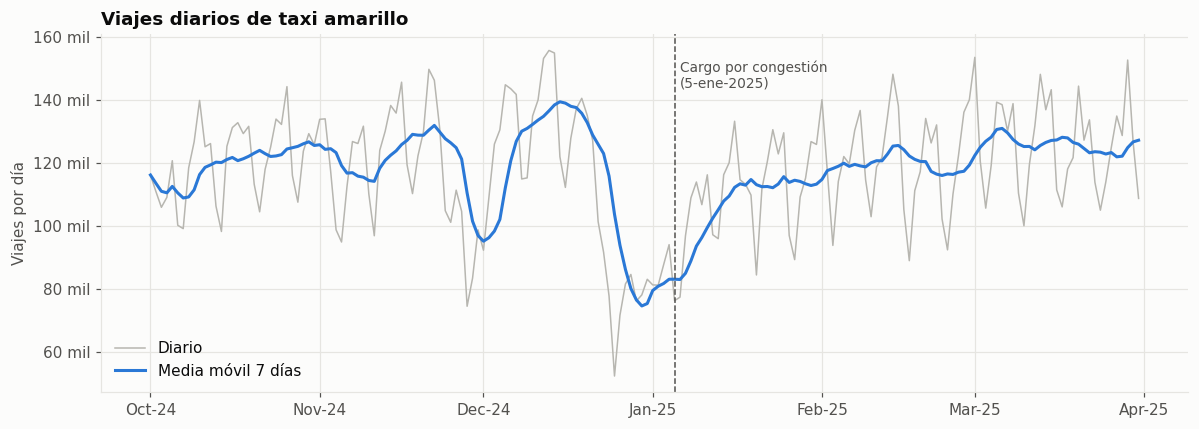

Media diaria: 117,694 viajes | máx: 155,722 | mín: 52,492
Días más bajos: 2024-12-25 (52,492), 2024-12-26 (71,769), 2024-11-28 (74,613)


In [2]:
d = rows("""
    select date, sum(trips) as trips from gold_demand_daily_area group by 1 order by 1""")
dates = [r["date"] for r in d]; trips = [r["trips"] for r in d]
ma7 = [sum(trips[max(0,i-6):i+1]) / len(trips[max(0,i-6):i+1]) for i in range(len(trips))]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(dates, trips, color="#b7b6b0", lw=1, label="Diario")
ax.plot(dates, ma7, color=BLUE, lw=2, label="Media móvil 7 días")
import datetime as dt
ax.axvline(dt.date(2025, 1, 5), color=INK2, lw=1, ls="--")
ax.text(dt.date(2025, 1, 6), max(trips)*0.98, "Cargo por congestión\n(5-ene-2025)", color=INK2, fontsize=9, va="top")
ax.set_title("Viajes diarios de taxi amarillo")
ax.set_ylabel("Viajes por día")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f} mil"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.legend(frameon=False, loc="lower left")
save(fig, "01_demanda_diaria")

low = sorted(d, key=lambda r: r["trips"])[:3]
print(f"Media diaria: {sum(trips)/len(trips):,.0f} viajes | máx: {max(trips):,} | mín: {min(trips):,}")
print("Días más bajos:", ", ".join(f"{r['date']} ({r['trips']:,})" for r in low))

## 2. ¿Cuándo se concentra la demanda?

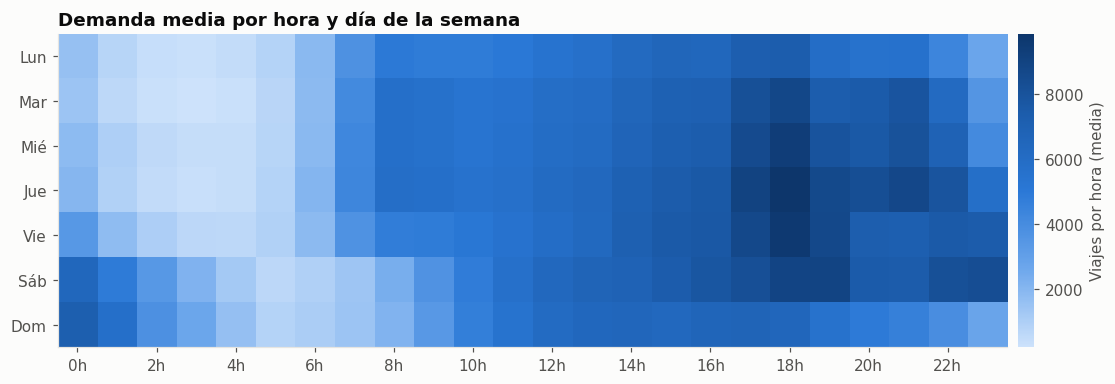

Pico: día 4 a las 18h (9,839 viajes/h) | Valle: día 2 a las 3h (204)
Ratio pico/valle: 48x


In [3]:
h = rows("""
    select dow, hour, avg(t) as trips from (
        select date, dow, hour, sum(trips) as t from gold_demand_zone_hour group by all)
    group by all""")
import numpy as np
M = np.zeros((7, 24))
for r in h: M[r["dow"]-1, r["hour"]] = r["trips"]

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(M, aspect="auto", cmap=SEQ)
ax.set_yticks(range(7), ["Lun","Mar","Mié","Jue","Vie","Sáb","Dom"])
ax.set_xticks(range(0, 24, 2), [f"{x}h" for x in range(0, 24, 2)])
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label("Viajes por hora (media)")
cb.outline.set_visible(False)
ax.set_title("Demanda media por hora y día de la semana")
save(fig, "02_heatmap_hora_dia")

pk = max(h, key=lambda r: r["trips"]); lo = min(h, key=lambda r: r["trips"])
print(f"Pico: día {pk['dow']} a las {pk['hour']}h ({pk['trips']:,.0f} viajes/h) | Valle: día {lo['dow']} a las {lo['hour']}h ({lo['trips']:,.0f})")
print(f"Ratio pico/valle: {pk['trips']/lo['trips']:.0f}x")

## 3. ¿Dónde se concentra la demanda?

In [4]:
z = rows("""
    select d.zone, d.area, sum(g.trips) as trips
    from gold_demand_zone_hour g join dim_zone d using (location_id)
    group by all order by trips desc""")
total = sum(r["trips"] for r in z)
acc = 0
for i, r in enumerate(z):
    acc += r["trips"]
    if acc / total >= 0.8:
        n80 = i + 1; break
print(f"{len(z)} zonas con viajes. El 80% de la demanda se concentra en {n80} zonas ({100*n80/len(z):.0f}% de las zonas).\n")
print(f"{'#':>2}  {'Zona':<32}{'Área':<16}{'Viajes':>12}{'% total':>9}")
for i, r in enumerate(z[:10], 1):
    print(f"{i:>2}  {r['zone'][:31]:<32}{r['area']:<16}{r['trips']:>12,}{100*r['trips']/total:>8.1f}%")
a = rows("select area, sum(trips) as trips from gold_demand_daily_area group by 1 order by 2 desc")
print("\nPor área:")
for r in a: print(f"  {r['area']:<16}{100*r['trips']/sum(x['trips'] for x in a):>6.1f}%")

260 zonas con viajes. El 80% de la demanda se concentra en 32 zonas (12% de las zonas).

 #  Zona                            Área                  Viajes  % total
 1  Upper East Side South           Frontera CBD       1,018,289     4.8%
 2  Midtown Center                  CBD (cargo)          986,115     4.6%
 3  Upper East Side North           Manhattan resto      921,325     4.3%
 4  JFK Airport                     Aeropuertos          847,498     4.0%
 5  Midtown East                    CBD (cargo)          717,474     3.4%
 6  Times Sq/Theatre District       CBD (cargo)          716,711     3.4%
 7  Penn Station/Madison Sq West    CBD (cargo)          711,341     3.3%
 8  Lincoln Square East             Frontera CBD         681,575     3.2%
 9  Midtown North                   CBD (cargo)          599,884     2.8%
10  LaGuardia Airport               Aeropuertos          593,801     2.8%

Por área:
  CBD (cargo)       58.1%
  Manhattan resto   15.6%
  Frontera CBD      14.8%
  Aeropu

## 4. ¿Qué pasó tras el cargo por congestión?

Comparamos la **media de viajes diarios** antes (1-oct a 20-dic-2024, sin festividades) y después (6-ene a 31-mar-2025) por área.

**Advertencia de diseño:** sin datos del año anterior, esta comparación mezcla el efecto del cargo con la estacionalidad invernal. Por eso se lee como *diferencias entre áreas*, no como variación absoluta.

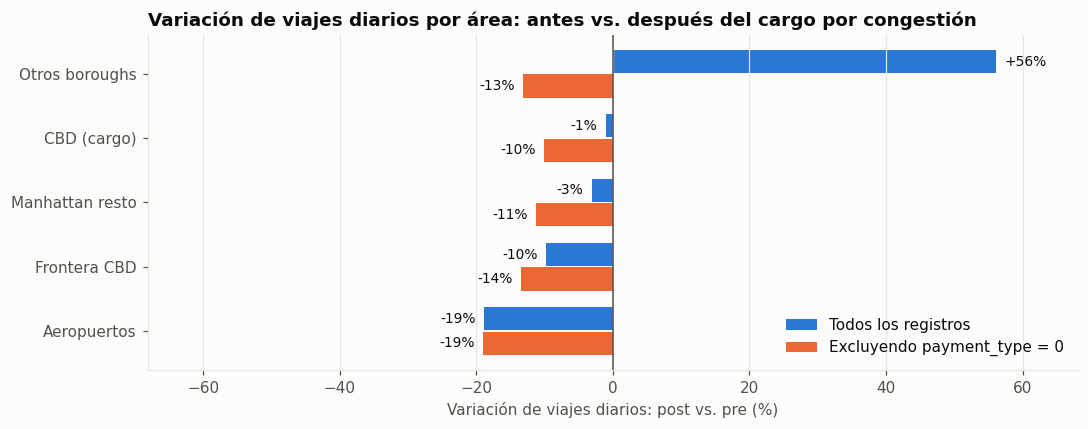

Aeropuertos      total  -18.8%   sin payment_type 0  -19.0%
Frontera CBD     total   -9.8%   sin payment_type 0  -13.5%
Manhattan resto  total   -3.1%   sin payment_type 0  -11.2%
CBD (cargo)      total   -1.0%   sin payment_type 0  -10.1%
Otros boroughs   total  +56.1%   sin payment_type 0  -13.1%


In [5]:
p = rows("""
    with s as (
        select s.pickup_date as d, z.area, s.is_payment_type_0 as pt0
        from silver_yellow_trips s join dim_zone z on z.location_id = s.pu_location_id
        where z.area <> 'Desconocida'),
    x as (
        select area,
               case when d between date '2024-10-01' and date '2024-12-20' then 'pre'
                    when d between date '2025-01-06' and date '2025-03-31' then 'post' end as per,
               d, pt0
        from s)
    select area,
        count(*) filter (where per='post') / count(distinct d) filter (where per='post')
      / (count(*) filter (where per='pre') / count(distinct d) filter (where per='pre')) - 1 as var_total,
        count(*) filter (where per='post' and not pt0) / count(distinct d) filter (where per='post')
      / (count(*) filter (where per='pre' and not pt0) / count(distinct d) filter (where per='pre')) - 1 as var_sin_pt0
    from x where per is not null group by 1 order by var_total""")

fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(p)); hgt = 0.36
b1 = ax.barh(y + hgt/2 + 0.01, [100*r["var_total"] for r in p], hgt, color=BLUE, label="Todos los registros")
b2 = ax.barh(y - hgt/2 - 0.01, [100*r["var_sin_pt0"] for r in p], hgt, color=ORANGE, label="Excluyendo payment_type = 0")
for bars in (b1, b2):
    for b in bars:
        v = b.get_width()
        ax.text(v + (1.2 if v >= 0 else -1.2), b.get_y() + b.get_height()/2, f"{v:+.0f}%",
                va="center", ha="left" if v >= 0 else "right", color=INK, fontsize=9)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(y, [r["area"] for r in p])
ax.set_xlabel("Variación de viajes diarios: post vs. pre (%)")
ax.set_title("Variación de viajes diarios por área: antes vs. después del cargo por congestión")
ax.grid(axis="y", visible=False)
lim = max(abs(100*r[k]) for r in p for k in ("var_total", "var_sin_pt0")) + 12
ax.set_xlim(-lim, lim)
ax.legend(frameon=False, loc="lower right")
save(fig, "04_variacion_por_area")
for r in p: print(f"{r['area']:<16} total {100*r['var_total']:+6.1f}%   sin payment_type 0 {100*r['var_sin_pt0']:+6.1f}%")

### ¿Por qué suben "Otros boroughs"? Un artefacto de la fuente, no un efecto real

El aumento coincide con el crecimiento de los registros `payment_type = 0` detectado en la limpieza (ver `reports/quality/DECISIONES_LIMPIEZA.md`).

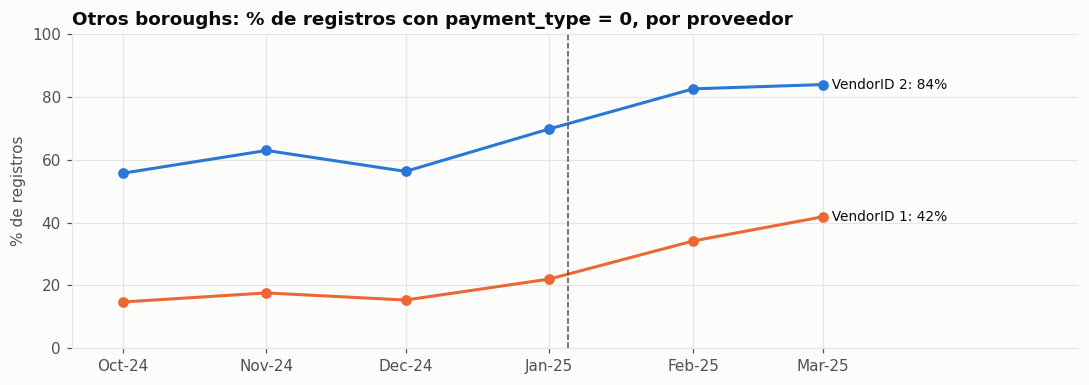

VendorID 1: 45,823 registros en Oct-24 -> 66,833 en Mar-25
VendorID 2: 76,027 registros en Oct-24 -> 186,514 en Mar-25


In [6]:
v = rows("""
    select date_trunc('month', s.pickup_date) as mes, s.vendor_id,
           avg(s.is_payment_type_0::int) as pct_pt0, count(*) as n
    from silver_yellow_trips s join dim_zone z on z.location_id = s.pu_location_id
    where z.area = 'Otros boroughs' and s.vendor_id in (1, 2)
    group by all order by 1""")
fig, ax = plt.subplots(figsize=(10, 3.6))
for vid, col in ((2, BLUE), (1, ORANGE)):
    s = [r for r in v if r["vendor_id"] == vid]
    xs = [r["mes"] for r in s]; ys = [100*r["pct_pt0"] for r in s]
    ax.plot(xs, ys, color=col, lw=2, marker="o", ms=6)
    ax.text(xs[-1], ys[-1], f"  VendorID {vid}: {ys[-1]:.0f}%", color=INK, va="center", fontsize=9)
ax.axvline(dt.datetime(2025, 1, 5), color=INK2, lw=1, ls="--")
ax.set_ylim(0, 100); ax.set_ylabel("% de registros")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.set_xlim(dt.datetime(2024, 9, 20), dt.datetime(2025, 4, 25))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[10,11,12,1,2,3]))
ax.set_title("Otros boroughs: % de registros con payment_type = 0, por proveedor")
save(fig, "05_payment_type0_otros_boroughs")
for vid in (1, 2):
    s = [r for r in v if r["vendor_id"] == vid]
    print(f"VendorID {vid}: {s[0]['n']:,} registros en {s[0]['mes']:%b-%y} -> {s[-1]['n']:,} en {s[-1]['mes']:%b-%y}")

## 5. Implicaciones para el modelo predictivo

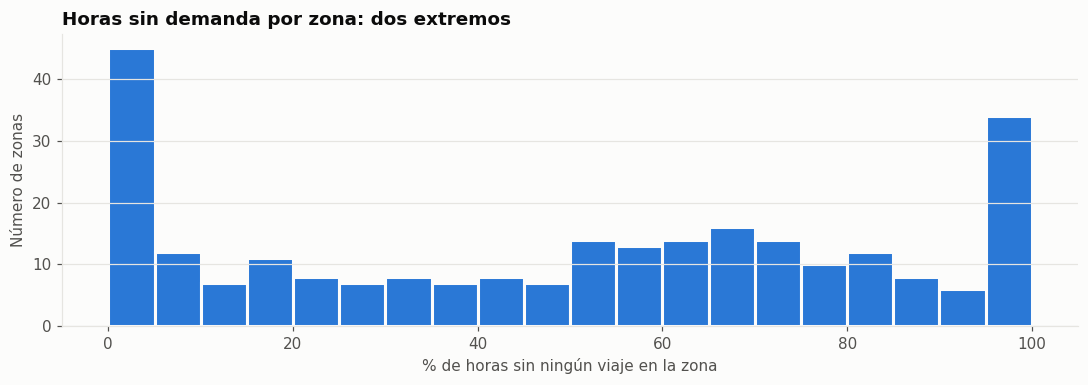

Zonas con < 10% de horas vacías: 57 de 261, concentran el 95.0% de los viajes.
Zonas con > 90% de horas vacías: 40


In [7]:
zz = rows("""
    select location_id, avg((trips = 0)::int) as pct_zero, sum(trips) as trips
    from gold_demand_zone_hour group by 1""")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist([100*r["pct_zero"] for r in zz], bins=20, color=BLUE, edgecolor=SURF, linewidth=2)
ax.set_xlabel("% de horas sin ningún viaje en la zona")
ax.set_ylabel("Número de zonas")
ax.set_title("Horas sin demanda por zona: dos extremos")
ax.grid(axis="x", visible=False)
save(fig, "06_horas_sin_demanda")
dense = [r for r in zz if r["pct_zero"] < 0.1]
share = sum(r["trips"] for r in dense) / sum(r["trips"] for r in zz)
print(f"Zonas con < 10% de horas vacías: {len(dense)} de {len(zz)}, concentran el {100*share:.1f}% de los viajes.")
print(f"Zonas con > 90% de horas vacías: {sum(r['pct_zero'] > 0.9 for r in zz)}")

## Conclusiones

1. **Volumen y estacionalidad.** Media de ~117.700 viajes/día. La demanda cae con fuerza en Acción de Gracias y Navidad (mínimo: 52.492 viajes el 25-dic) y se recupera de forma sostenida entre enero y marzo.
2. **Patrón horario muy marcado.** Pico los jueves a las 18 h (~9.800 viajes/h) frente a un valle de ~200 viajes/h los martes a las 3 h: **48 veces más**. Las madrugadas de sábado y domingo son la excepción nocturna.
3. **Concentración geográfica.** 32 zonas (12%) generan el 80% de la demanda; el perímetro del cargo por congestión concentra el **58%** de los viajes.
4. **Cargo por congestión: la conclusión ingenua es falsa.** La comparación directa sugiere que la demanda se desplazó a otros boroughs (+56%). Es un **artefacto de la fuente**: el aumento se explica por el crecimiento de los registros `payment_type = 0`. Excluyéndolos, todas las áreas caen entre un 10% y un 19%, y **el CBD (−10%) no cae más que el resto de Manhattan (−11%)**. Con estos datos no hay evidencia de que el cargo haya reducido los viajes de taxi amarillo dentro del CBD más que fuera.
   - *Limitación:* sin datos del año anterior, la comparación mezcla efecto y estacionalidad. Siguiente paso: incorporar ene-mar 2024 para una comparación interanual por diferencias en diferencias.
5. **Implicaciones para el modelo.**
   - El 49% de las combinaciones zona-hora tiene **cero viajes**, pero 57 zonas concentran el 95% de la demanda → modelar a nivel zona-hora con una función de pérdida para conteos (Poisson/Tweedie) y evaluar por separado zonas densas e intermitentes.
   - `payment_type`, pasajeros y RatecodeID **no se usarán como variables**: cambiaron de composición en ene-2025.
   - El baseline a superar será el *naive estacional* (misma hora de la semana anterior).